In [3]:
import sys

import numpy as np
import matplotlib.pyplot as plt
import sklearn

from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

plt.rcParams.update(
    {"figure.figsize": (6, 4), "axes.grid": True, "grid.alpha": 0.2, "font.size": 11}
)
KOLORY = ["#2878B5", "#D95319", "#498A38"]
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

# Prosty test najważniejszych bibliotek
test_X = np.array([[0.0, 0.0], [0.2, 0.1], [1.0, 1.0], [1.2, 0.9]])
test_y = np.array([0, 0, 1, 1])
test_model = LinearDiscriminantAnalysis().fit(test_X, test_y)
assert np.array_equal(test_model.predict(test_X), test_y)
test_fig = plt.figure()
plt.close(test_fig)
print("Środowisko działa poprawnie.")

def dane_dwie_klasy(seed=42, n_na_klase=80):
    rng = np.random.default_rng(seed)
    kowariancja = np.array([[1.0, 0.75], [0.75, 1.2]])
    X0 = rng.multivariate_normal([-1.0, 0.0], kowariancja, n_na_klase)
    X1 = rng.multivariate_normal([1.0, 0.8], kowariancja, n_na_klase)
    return np.vstack([X0, X1]), np.repeat([0, 1], n_na_klase)


def rysuj_klasy(X, y, ax, nazwy=None):
    for k in np.unique(y):
        ax.scatter(
            *X[y == k].T,
            s=30,
            color=KOLORY[int(k)],
            alpha=0.8,
            label=f"Klasa {k}" if nazwy is None else nazwy[int(k)],
        )
    ax.set(xlabel="$x_1$", ylabel="$x_2$")
    ax.legend()


def rysuj_svm(model, X, y, ax, tytul):
    """Model to dopasowany Pipeline: StandardScaler + binarny SVC."""
    dol, gora = X.min(axis=0) - 0.6, X.max(axis=0) + 0.6
    xx, yy = np.meshgrid(
        np.linspace(dol[0], gora[0], 180), np.linspace(dol[1], gora[1], 180)
    )
    siatka = np.column_stack([xx.ravel(), yy.ravel()])
    pred = model.predict(siatka).reshape(xx.shape)
    ax.contourf(
        xx,
        yy,
        pred,
        levels=[-0.5, 0.5, 1.5],
        alpha=0.12,
        cmap=ListedColormap(KOLORY[:2]),
    )
    f = model.decision_function(siatka).reshape(xx.shape)
    ax.contour(
        xx,
        yy,
        f,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"],
        linewidths=1,
    )
    rysuj_klasy(X, y, ax)
    # SVC widzi cechy standaryzowane; na wykresie pokazujemy oryginalne jednostki.
    sv = model.named_steps["standardscaler"].inverse_transform(
        model.named_steps["svc"].support_vectors_
    )
    ax.scatter(
        *sv.T,
        s=85,
        facecolors="none",
        edgecolors="black",
        linewidths=0.8,
        label="Wektory podpierające",
    )
    uchwyty, etykiety = ax.get_legend_handles_labels()
    uchwyty += [
        Line2D([0], [0], color="black"),
        Line2D([0], [0], color="black", linestyle="--"),
    ]
    ax.legend(uchwyty, etykiety + ["f(x) = 0", "f(x) = ±1"], fontsize=8)
    ax.set(title=tytul, xlim=(dol[0], gora[0]), ylim=(dol[1], gora[1]))


Python: 3.13.18
NumPy: 2.5.4
scikit-learn: 1.9.1
Środowisko działa poprawnie.


Trening: (112, 2) Test: (48, 2)


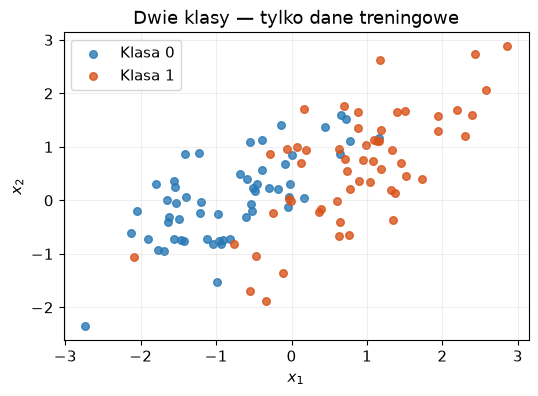

In [4]:
X, y = dane_dwie_klasy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print("Trening:", X_train.shape, "Test:", X_test.shape)
fig, ax = plt.subplots()
rysuj_klasy(X_train, y_train, ax)
ax.set_title("Dwie klasy — tylko dane treningowe")
plt.show()
